# P3.06 — What the State spends on housing

**Questions:** RQ8.1 (how much does government spend on housing programmes, rental support, subsidies and public housing?),
with a peer comparison that bears on RQ6.5.

General-government expenditure by function (COFOG, national accounts, annual): **housing development** (GF0601, public housing
included) and **housing in social protection** (GF1006, housing allowances and rent subsidies). Their sum is "housing support"
here. What is not in it: tax expenditures (IRS deductions, IMT and IMI exemptions), loan guarantees, and anything booked under
another function. Housing and community amenities (GF06) also holds water supply and street lighting, so it is not used.
Programme-level cost-effectiveness (RQ8.2) needs administrative data that are not in the project.

In [1]:
from pthousing.analysis import spending
from pthousing.data import interim
from pthousing.viz import charts, style

style.apply_style()
sp = interim.read("eurostat_housing_spending")
pt = spending.portugal_frame(sp, interim.read("ine_cpi"), interim.read("eurostat_property_tax"))
shares = spending.support_shares(sp)
print(f"{pt.index.min()}-{pt.index.max()}; countries {sorted(sp['geo'].unique())}")

1995-2024; countries ['DE', 'ES', 'EU27_2020', 'FR', 'IE', 'IT', 'PT']


## Step 1 — Portugal
Real spending (constant euros of the base year) by kind, and as a share of GDP.

,housing_development_real_eur_m,housing_benefits_real_eur_m,support_real_eur_m,support_gdp_pct,spending_per_tax_pct
year,,,,,
1995,167.28,741.36,908.65,0.53,79.49
2000,851.44,1005.89,1857.33,0.88,95.48
2005,404.13,847.62,1251.75,0.56,58.47
2010,325.81,563.88,889.70,0.38,40.22
2015,223.73,522.57,746.30,0.35,29.23
2019,333.13,567.00,900.13,0.36,28.16
2022,478.71,585.43,1064.14,0.41,30.14
2023,642.35,874.02,1516.37,0.55,44.31
2024,666.80,947.80,1614.60,0.55,48.16


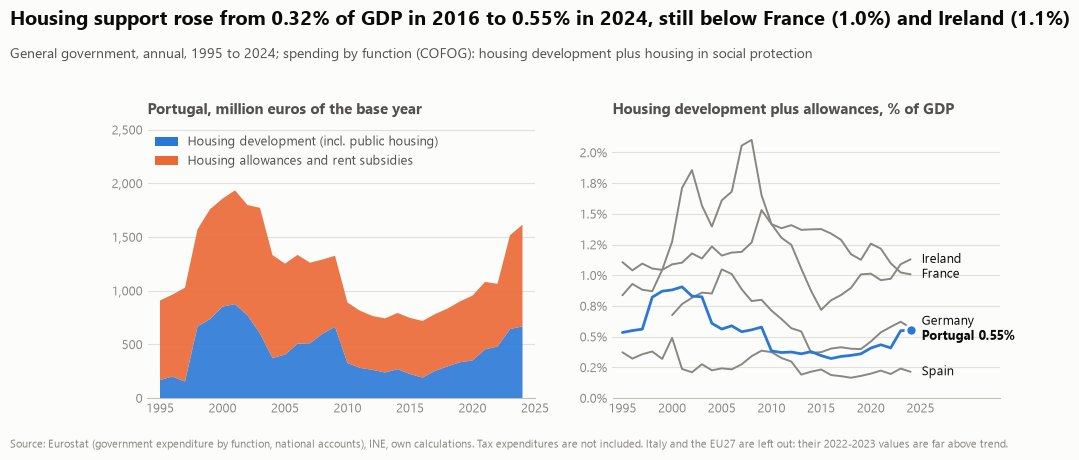

In [2]:
peers = {"DE": "Germany", "ES": "Spain", "FR": "France", "IE": "Ireland"}
fig = charts.housing_spending(pt, shares, peers)
style.save_fig(fig, "p3", "housing_spending")
years = [1995, 2000, 2005, 2010, 2015, 2019, 2022, 2023, 2024]
cols = [
    "housing_development_real_eur_m",
    "housing_benefits_real_eur_m",
    "support_real_eur_m",
    "support_gdp_pct",
    "spending_per_tax_pct",
]
levels = pt.loc[years, cols]
style.save_table(levels.round(2).reset_index(), "p3", "housing_spending_levels")
series = pt[["housing_development_real_eur_m", "housing_benefits_real_eur_m", "support_gdp_pct"]]
style.save_table(
    series.round(2).reset_index(), "p3", "housing_spending_series"
)  # every year, for the dashboard
levels.round(2)

## Step 2 — Against the peers
Housing support as a share of GDP. Italy (2022-2023: 3.0% and 4.1%) and the EU27 aggregate are far above their trend in those
years; this is likely the booking of building-renovation tax credits as expenditure, which is not verified here, so they stay in the
table but out of the figure and the averages.

In [3]:
table = shares.loc[[1995, 2000, 2005, 2010, 2015, 2019, 2022, 2023, 2024]]
average = shares.loc[2015:2024].drop(columns=["IT", "EU27_2020"]).mean().rename("mean_2015_2024")
style.save_table(table.round(2).reset_index(), "p3", "housing_support_peers")
style.save_table(
    average.round(2).rename_axis("geo").reset_index(), "p3", "housing_support_peer_means"
)
print(average.round(2).to_string())
table.round(2)

geo
DE    0.48
ES    0.20
FR    1.19
IE    0.94
PT    0.41


geo,DE,ES,EU27_2020,FR,IE,IT,PT
year,,,,,,,
1995,NaN,0.37,NaN,1.11,0.84,NaN,0.53
2000,0.67,0.49,NaN,1.09,1.27,NaN,0.88
2005,1.05,0.24,NaN,1.16,1.61,0.12,0.56
2010,0.71,0.37,0.66,1.42,1.42,0.15,0.38
2015,0.37,0.23,0.55,1.38,0.72,0.14,0.35
2019,0.40,0.18,0.49,1.13,1.01,0.11,0.36
2022,0.58,0.20,0.89,1.10,0.97,2.95,0.41
2023,0.62,0.24,1.07,1.02,1.09,4.10,0.55
2024,0.57,0.21,0.59,1.01,1.13,0.41,0.55


## Step 3 — Scale against property-tax revenue
For scale only: IMI and IMT revenue (`p3_04`) goes to councils, housing support is mostly central. Housing support has been 27%
to 36% of what the two property taxes raise in 2013-2022 and 44% to 48% in 2023-2024.

In [4]:
scale = pt.loc[2013:, ["support_eur_m", "property_tax_eur_m", "spending_per_tax_pct"]]
style.save_table(scale.round(1).reset_index(), "p3", "housing_spending_vs_property_tax")
scale.round(1)

,support_eur_m,property_tax_eur_m,spending_per_tax_pct
year,,,
2013,614.2,1709.5,35.9
2014,654.1,1959.2,33.4
2015,619.1,2117.8,29.2
2016,599.1,2175.7,27.5
2017,661.5,2451.4,27.0
2018,711.7,2640.7,27.0
2019,771.7,2740.6,28.2
2020,817.8,2597.7,31.5
2021,938.9,2946.5,31.9


## Key numbers

In [5]:
p = pt
print(
    f"2024: housing development {p.loc[2024, 'housing_development_eur_m']:,.0f} EUR m, allowances {p.loc[2024, 'housing_benefits_eur_m']:,.0f}, "
    f"together {p.loc[2024, 'support_eur_m']:,.0f} = {p.loc[2024, 'support_gdp_pct']:.2f}% of GDP"
)
low = p.loc[2010:, "support_gdp_pct"].idxmin()
print(
    f"share of GDP: 1995 {p.loc[1995, 'support_gdp_pct']:.2f}%, peak {p['support_gdp_pct'].max():.2f}% ({p['support_gdp_pct'].idxmax()}), "
    f"low since 2010 {p.loc[low, 'support_gdp_pct']:.2f}% ({low}), 2024 {p.loc[2024, 'support_gdp_pct']:.2f}%"
)
print(
    f"real housing development {p.loc[2015, 'housing_development_real_eur_m']:,.0f} (2015) -> {p.loc[2024, 'housing_development_real_eur_m']:,.0f} (2024) EUR m: {100 * (p.loc[2024, 'housing_development_real_eur_m'] / p.loc[2015, 'housing_development_real_eur_m'] - 1):+.0f}%; "
    f"allowances {p.loc[2015, 'housing_benefits_real_eur_m']:,.0f} -> {p.loc[2024, 'housing_benefits_real_eur_m']:,.0f}: {100 * (p.loc[2024, 'housing_benefits_real_eur_m'] / p.loc[2015, 'housing_benefits_real_eur_m'] - 1):+.0f}%; "
    f"2022 -> 2023 allowances {100 * (p.loc[2023, 'housing_benefits_eur_m'] / p.loc[2022, 'housing_benefits_eur_m'] - 1):+.0f}% nominal"
)
print(
    "2024 peers (% of GDP): "
    + ", ".join(
        f"{peers.get(g, g)} {shares.loc[2024, g]:.2f}"
        for g in ["DE", "ES", "FR", "IE", "IT", "EU27_2020"]
    )
    + f"; Portugal {shares.loc[2024, 'PT']:.2f}"
)
print(
    f"2015-2024 mean: Portugal {average['PT']:.2f}% against "
    + ", ".join(f"{peers[g]} {average[g]:.2f}%" for g in peers)
)
print(
    f"housing support as a share of IMI plus IMT: 2015 {p.loc[2015, 'spending_per_tax_pct']:.0f}%, 2022 {p.loc[2022, 'spending_per_tax_pct']:.0f}%, 2024 {p.loc[2024, 'spending_per_tax_pct']:.0f}%"
)

2024: housing development 667 EUR m, allowances 948, together 1,615 = 0.55% of GDP
share of GDP: 1995 0.53%, peak 0.91% (2001), low since 2010 0.32% (2016), 2024 0.55%
real housing development 224 (2015) -> 667 (2024) EUR m: +198%; allowances 523 -> 948: +81%; 2022 -> 2023 allowances +56% nominal
2024 peers (% of GDP): Germany 0.57, Spain 0.21, France 1.01, Ireland 1.13, IT 0.41, EU27_2020 0.59; Portugal 0.55
2015-2024 mean: Portugal 0.41% against Germany 0.48%, Spain 0.20%, France 1.19%, Ireland 0.94%
housing support as a share of IMI plus IMT: 2015 29%, 2022 30%, 2024 48%
